# Variance Reduction

Pricing in the Black-Scholes model with crude Monte Carlo, antithetic variables, a control variate, and importance sampling with an adaptively learned drift.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

rng = np.random.default_rng(0)

## 1. Option on the discrete maximum

Payoff $\big(\max_{0\le j\le J} S_{t_j} - K S_T\big)^+$ with $S_0 = 100$, $r = 0.02$, $\sigma = 0.25$, $T = 2$, $J = 24$. All estimators use the same number $M$ of payoff evaluations.

In [2]:
S0, r, sigma, T, J = 100.0, 0.02, 0.25, 2.0, 24
M = 50_000
disc = np.exp(-r * T)

def paths(G):
    dt = T / J
    log_incr = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * G
    return S0 * np.exp(np.concatenate([np.zeros((len(G), 1)), np.cumsum(log_incr, axis=1)], axis=1))

def max_payoff(S, K):
    return np.maximum(S.max(axis=1) - K * S[:, -1], 0.0)

def summary(X):
    return X.mean(), 1.96 * X.std(ddof=1) / np.sqrt(len(X))

def crude(K, rng):
    return summary(disc * max_payoff(paths(rng.standard_normal((M, J))), K))

def antithetic(K, rng):
    G = rng.standard_normal((M // 2, J))
    return summary(disc * 0.5 * (max_payoff(paths(G), K) + max_payoff(paths(-G), K)))

def control_variate(K, rng):
    S = paths(rng.standard_normal((M, J)))
    X = disc * max_payoff(S, K)
    Y = S[:, -1] - S0 * np.exp(r * T)
    b = np.cov(X, Y)[0, 1] / Y.var(ddof=1)
    return summary(X - b * Y)

for name, method in [("Crude", crude), ("Antithetic", antithetic), ("Control variate", control_variate)]:
    price, ci = method(1.2, rng)
    print(f"{name:16s} {price:.4f} ± {ci:.4f}")

Crude            11.4333 ± 0.1306
Antithetic       11.4424 ± 0.0923
Control variate  11.5039 ± 0.1011


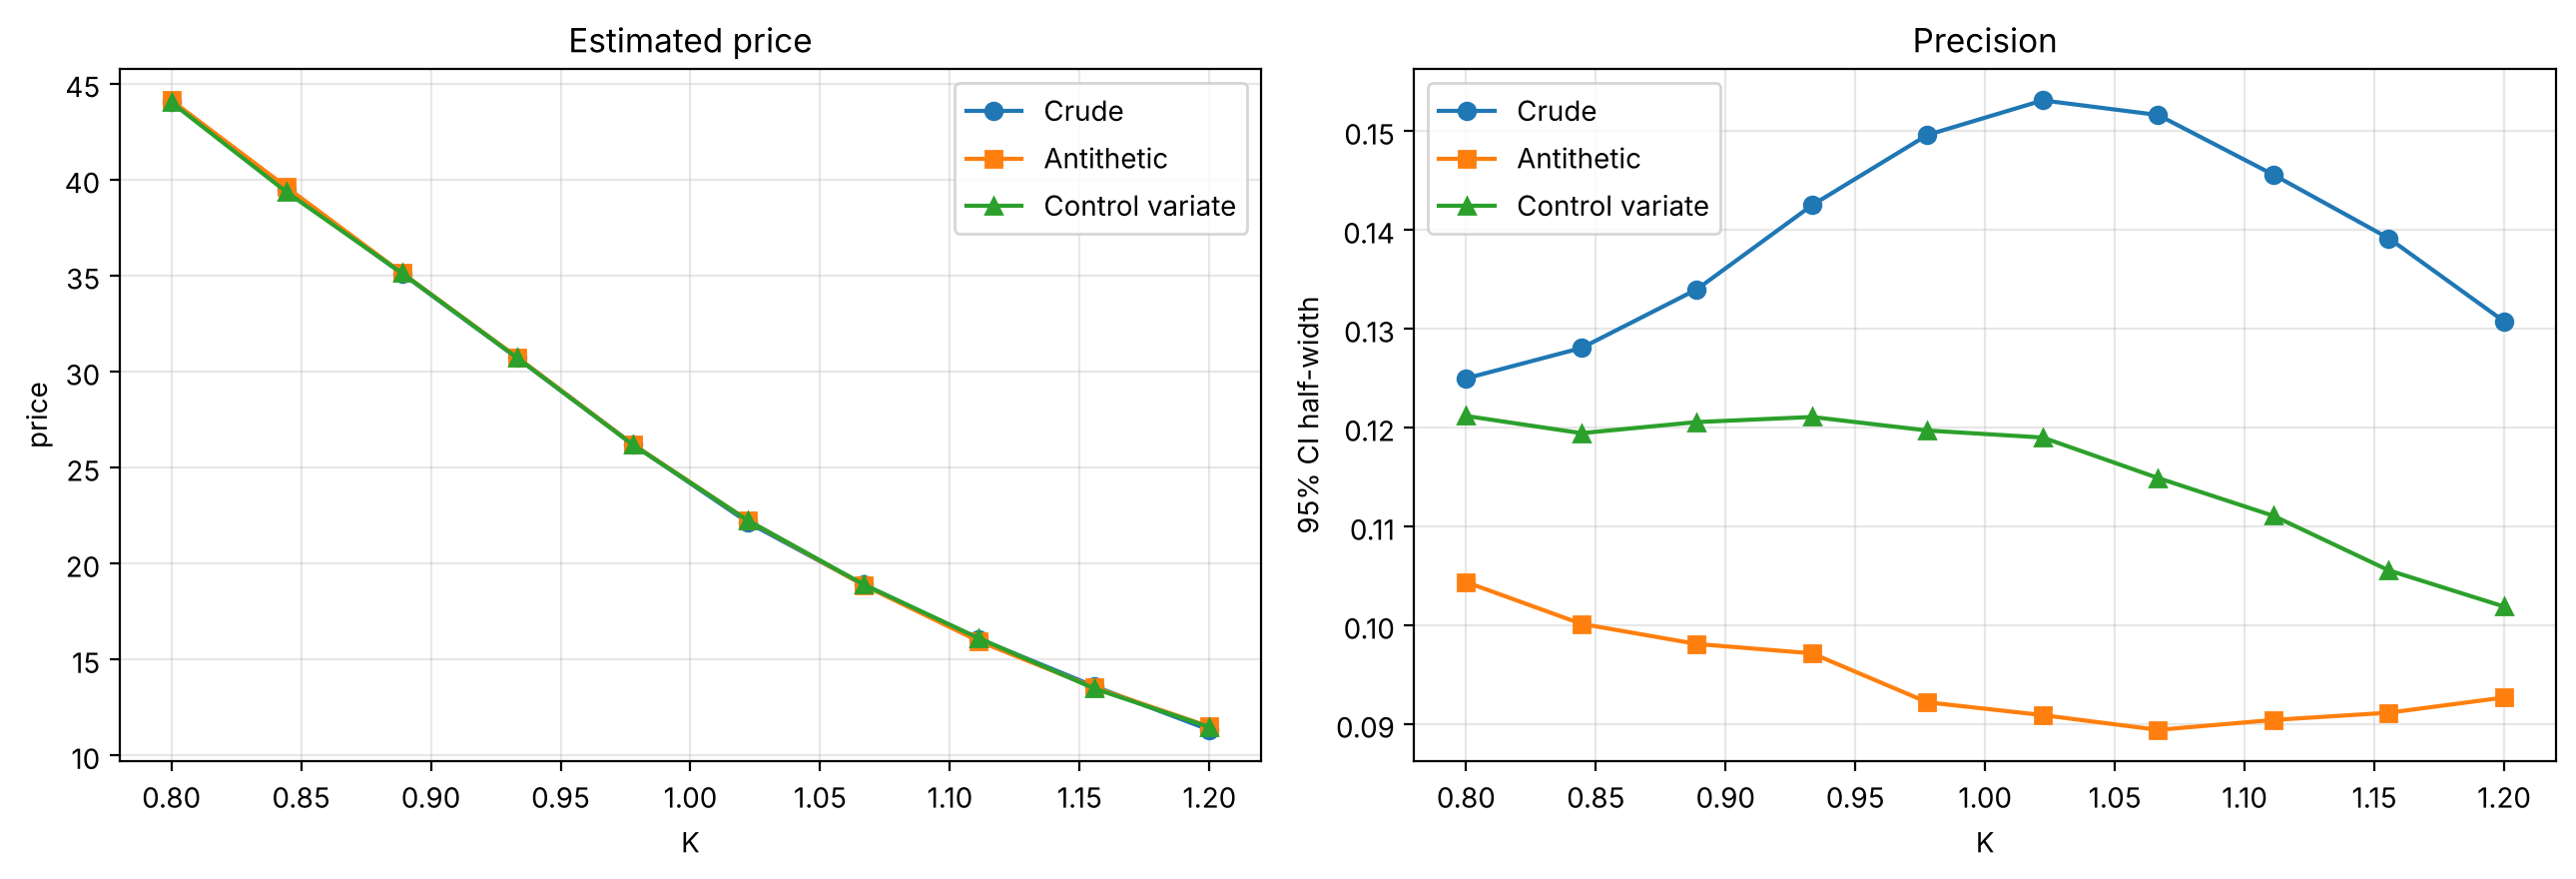

In [3]:
strikes = np.linspace(0.8, 1.2, 10)
methods = [("Crude", crude, "o-"), ("Antithetic", antithetic, "s-"), ("Control variate", control_variate, "^-")]
results = {name: np.array([method(K, rng) for K in strikes]) for name, method, _ in methods}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, _, style in methods:
    ax1.plot(strikes, results[name][:, 0], style, label=name)
    ax2.plot(strikes, results[name][:, 1], style, label=name)
ax1.set(xlabel="K", ylabel="price", title="Estimated price")
ax2.set(xlabel="K", ylabel="95% CI half-width", title="Precision")
for ax in (ax1, ax2):
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Adaptive importance sampling for a call

Call with $S_0 = 100$, $K = 120$, $r = 0.03$, $\sigma = 0.2$, $T = 2$. Writing the discounted payoff as $\psi(G)$ with $G \sim \mathcal N(0,1)$,
$$\mathbb E[\psi(G)] = \mathbb E\big[\psi(G+\theta)\,e^{-\theta G - \theta^2/2}\big],$$
and the variance is minimized by the $\theta$ solving $\mathbb E\big[(\theta - G)\,\psi(G)^2 e^{-\theta G + \theta^2/2}\big] = 0$. This root is found with a Robbins-Monro algorithm with random truncations.

In [4]:
S0, K, r, sigma, T = 100.0, 120.0, 0.03, 0.2, 2.0

d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
bs_price = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sigma * np.sqrt(T))

def psi(g):
    return np.exp(-r * T) * np.maximum(S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * g) - K, 0.0)

def U(theta, g):
    return (theta - g) * psi(g)**2 * np.exp(-theta * g + 0.5 * theta**2)

def robbins_monro(n, gamma, rng, beta=0.75, theta0=0.0):
    thetas = np.empty(n)
    theta, alpha = theta0, 1
    for i in range(n):
        candidate = theta - gamma / (i + 500)**beta * U(theta, rng.standard_normal())
        if candidate**2 <= np.log(alpha + 1):
            theta = candidate
        else:
            theta, alpha = theta0, alpha + 1
        thetas[i] = theta
    return thetas

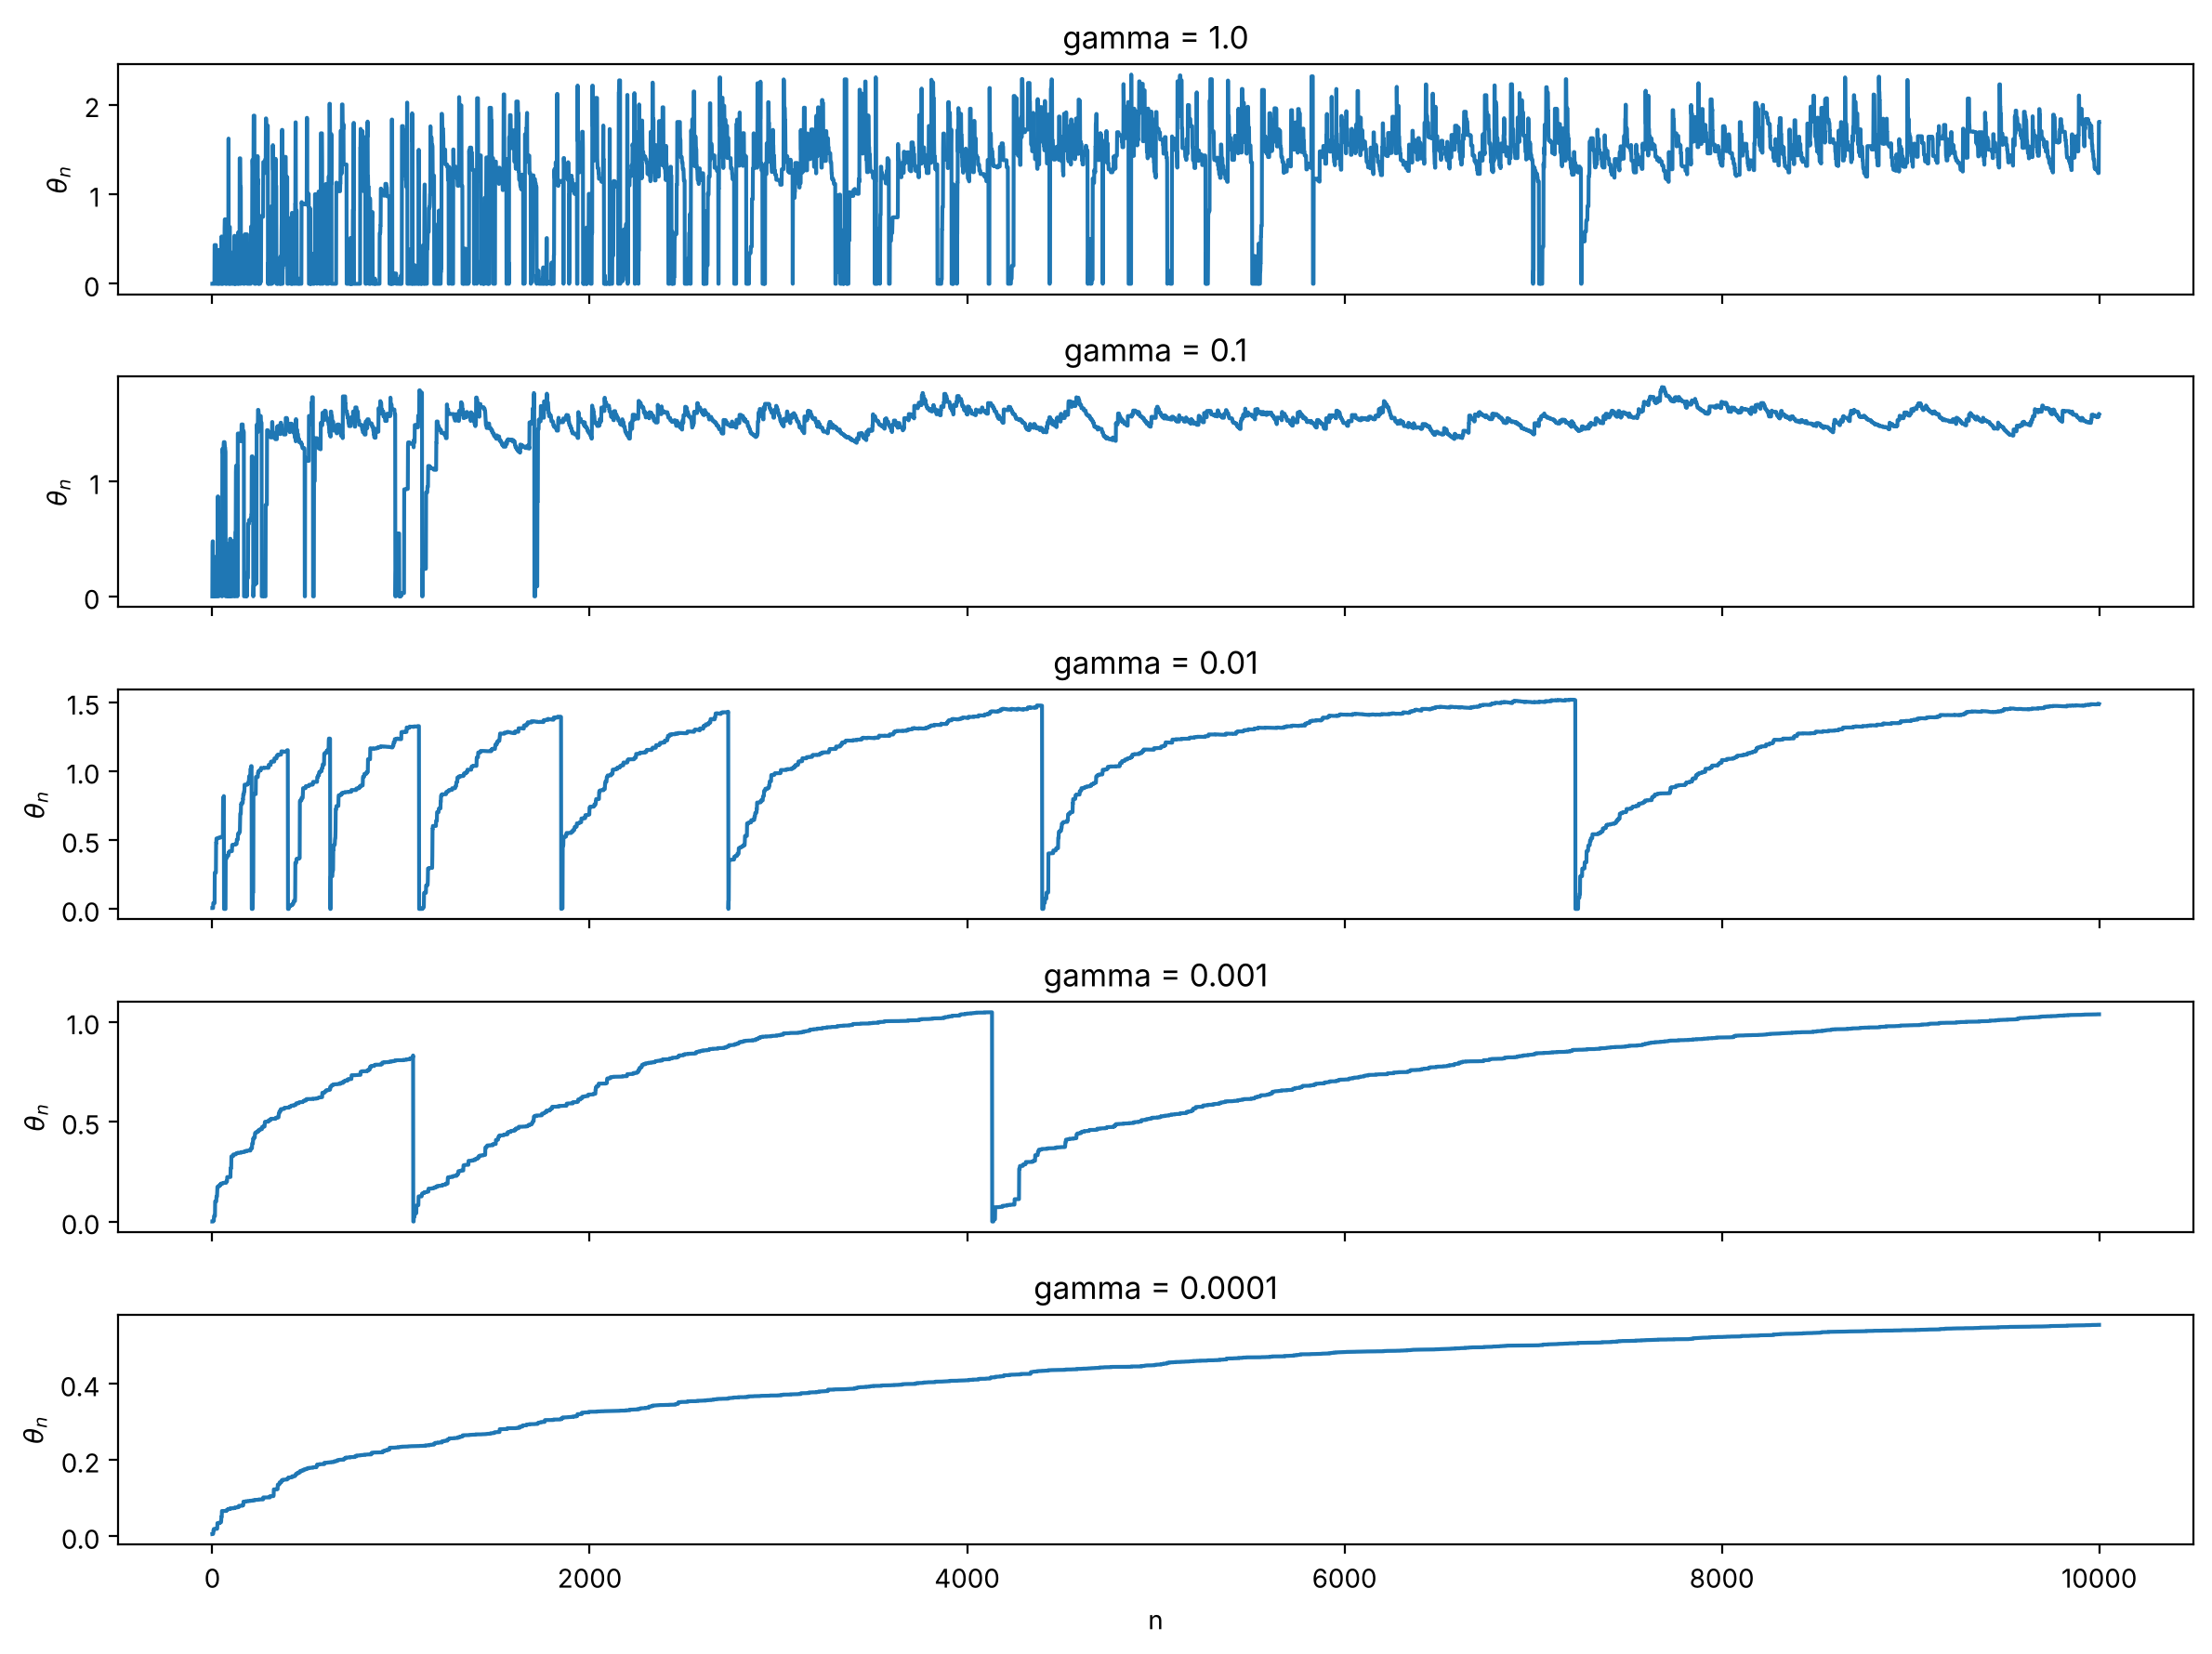

In [5]:
N = 10_000
gammas = [1.0, 0.1, 0.01, 0.001, 0.0001]
fig, axes = plt.subplots(len(gammas), sharex=True, figsize=(12, 9))
for ax, gamma in zip(axes, gammas):
    ax.plot(robbins_monro(N, gamma, rng))
    ax.set_ylabel(r"$\theta_n$"); ax.set_title(f"gamma = {gamma}")
axes[-1].set_xlabel("n")
plt.tight_layout(); plt.show()

In [6]:
M = 100_000
thetas = robbins_monro(N, 0.1, rng)
theta_bar = thetas.mean()

def importance_sampling(theta, rng):
    G = rng.standard_normal(M)
    return summary(psi(G + theta) * np.exp(-theta * G - 0.5 * theta**2))

G = rng.standard_normal(M // 2)
estimates = [
    ("Crude", summary(psi(rng.standard_normal(M)))),
    ("Antithetic", summary(0.5 * (psi(G) + psi(-G)))),
    (f"IS, last theta = {thetas[-1]:.3f}", importance_sampling(thetas[-1], rng)),
    (f"IS, averaged theta = {theta_bar:.3f}", importance_sampling(theta_bar, rng)),
]
print(f"Black-Scholes price: {bs_price:.4f}")
for name, (price, ci) in estimates:
    print(f"{name:30s} {price:.4f} ± {ci:.4f}")

Black-Scholes price: 6.5660
Crude                          6.5643 ± 0.0955
Antithetic                     6.5214 ± 0.0864
IS, last theta = 1.459         6.5660 ± 0.0252
IS, averaged theta = 1.505     6.5570 ± 0.0250


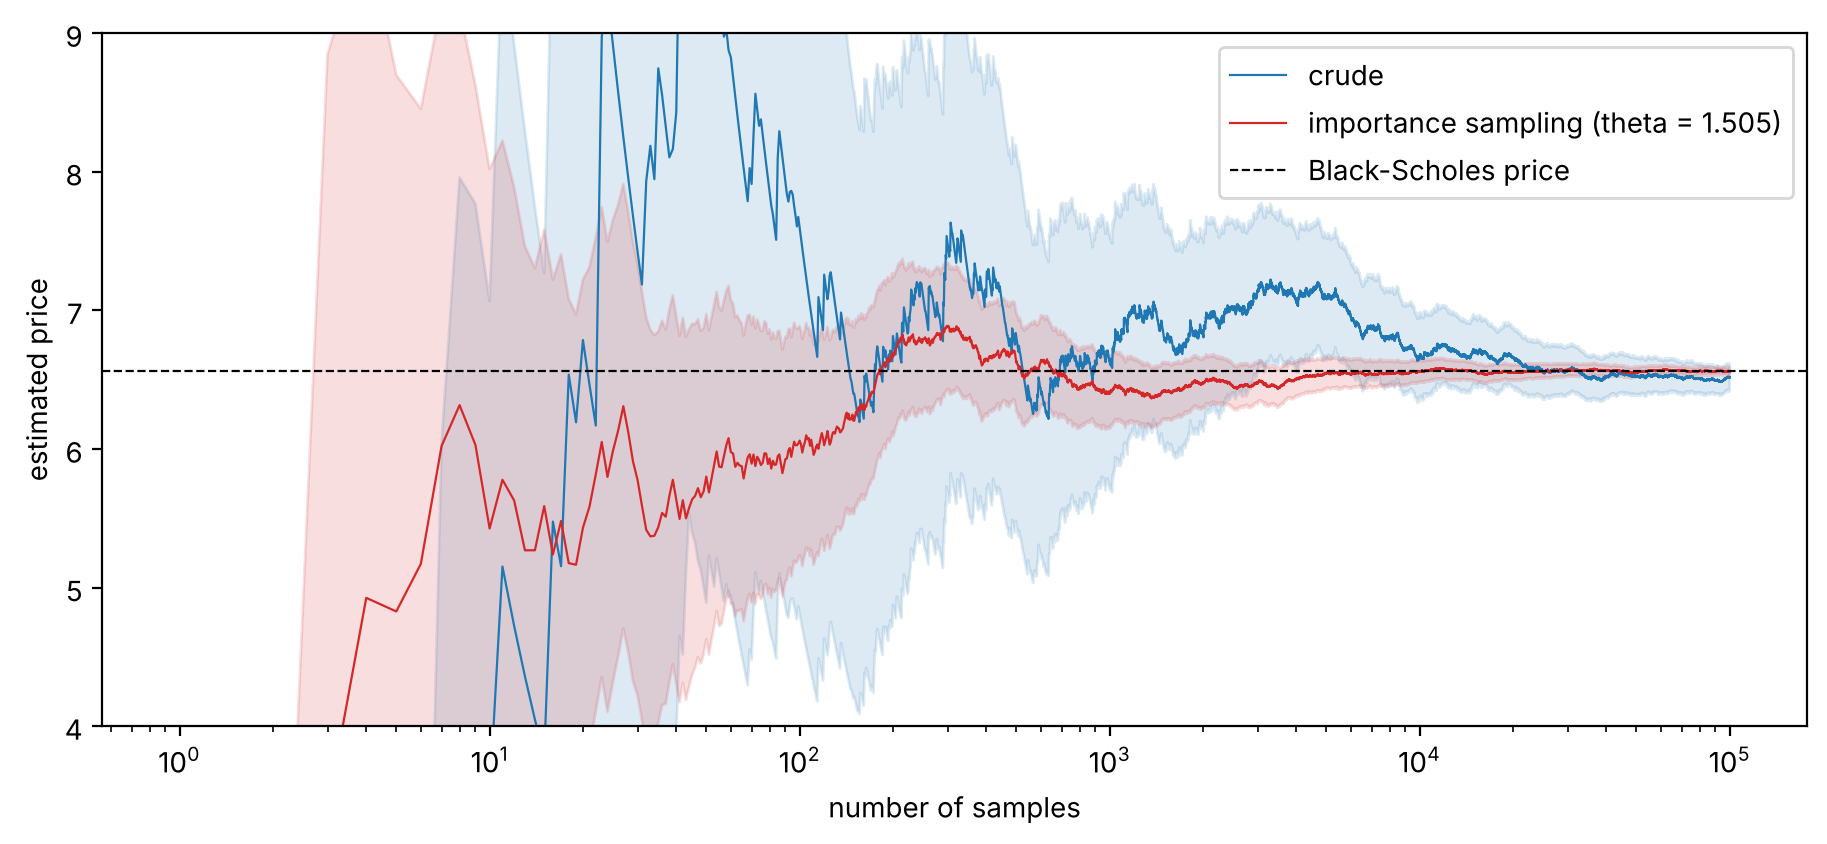

In [7]:
def running(X):
    n = np.arange(1, len(X) + 1)
    mean = np.cumsum(X) / n
    var = np.cumsum(X**2) / n - mean**2
    return n, mean, 1.96 * np.sqrt(np.maximum(var, 0) / n)

G1, G2 = rng.standard_normal(M), rng.standard_normal(M)
fig, ax = plt.subplots(figsize=(11, 4.5))
for X, label, color in [(psi(G1), "crude", "tab:blue"),
                        (psi(G2 + theta_bar) * np.exp(-theta_bar * G2 - 0.5 * theta_bar**2),
                         f"importance sampling (theta = {theta_bar:.3f})", "tab:red")]:
    n, mean, ci = running(X)
    ax.plot(n, mean, color=color, lw=0.8, label=label)
    ax.fill_between(n, mean - ci, mean + ci, color=color, alpha=0.15)
ax.axhline(bs_price, ls="--", color="k", lw=0.8, label="Black-Scholes price")
ax.set_xscale("log"); ax.set_ylim(4, 9)
ax.set_xlabel("number of samples"); ax.set_ylabel("estimated price"); ax.legend()
plt.show()